# Stage 5 — Measuring cracks

Crack segmentation and measurement project. Explanations: see the study guide.

In [1]:
# Cell 1 — Install, import and settings
%pip install -q segmentation-models-pytorch

from pathlib import Path
import json
import os
import re

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from skimage.morphology import skeletonize
import torch
from torch.utils.data import Dataset, DataLoader
import albumentations as A
from albumentations.pytorch import ToTensorV2
import segmentation_models_pytorch as smp
from tqdm.auto import tqdm

DATA_ROOT = Path("/kaggle/input")
OUT_DIR = Path("/kaggle/working")
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
PAD = 416
BORDER = (PAD - 400) // 2
MIN_CRACK_PX = 300        # measure only images with a clear crack in both label and prediction
LIMIT_MM = 0.3            # Eurocode 2 recommended crack-width limit for most exposure classes
rng = np.random.default_rng(0)

found = [Path(r) / f for r, _, fs in os.walk(DATA_ROOT, followlinks=True) for f in fs if f == "thresholds.json"]
THRESHOLD = float(next(iter(json.load(open(found[0])).values()))) if found else 0.35
print("device:", DEVICE, "| threshold:", THRESHOLD, "(from Stage 4)" if found else "(default)")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 3.3 MB/s eta 0:00:0000:01
Note: you may need to restart the kernel to use updated packages.
device: cuda | threshold: 0.35 (from Stage 4)


In [2]:
# Cell 2 — Measurement functions
def skeleton_length(skel):
    """Length of a 1-pixel-wide centre line: straight steps count 1, diagonal steps count sqrt(2)."""
    s = skel.astype(np.uint8)
    straight = (s[:, :-1] & s[:, 1:]).sum() + (s[:-1, :] & s[1:, :]).sum()
    diagonal = (s[:-1, :-1] & s[1:, 1:]).sum() + (s[:-1, 1:] & s[1:, :-1]).sum()
    return float(straight + np.sqrt(2) * diagonal)

def measure_crack(mask, min_px=50):
    """Length and width (in pixels) of all cracks in a binary mask."""
    mask = mask.astype(bool)
    if mask.sum() < min_px:
        return None
    dist = cv2.distanceTransform(mask.astype(np.uint8), cv2.DIST_L2, cv2.DIST_MASK_PRECISE)
    skel = skeletonize(mask)
    widths = 2 * dist[skel] - 1          # distance to the nearest edge, both sides, minus the centre pixel
    return {
        "length_px": skeleton_length(skel),
        "median_w": float(np.median(widths)),
        "p90_w": float(np.percentile(widths, 90)),     # a robust "maximum" width
        "skeleton": skel, "widths": widths,
    }

             mean   std  error
true_width                    
1            1.00  0.00   0.00
2            1.95  0.36  -0.05
3            3.05  0.15   0.05
4            3.53  0.26  -0.47
5            4.69  0.11  -0.31
6            6.03  0.36   0.03
8            7.54  0.18  -0.46
10           9.88  0.22  -0.12
12          11.68  0.06  -0.32
15          14.54  0.16  -0.46


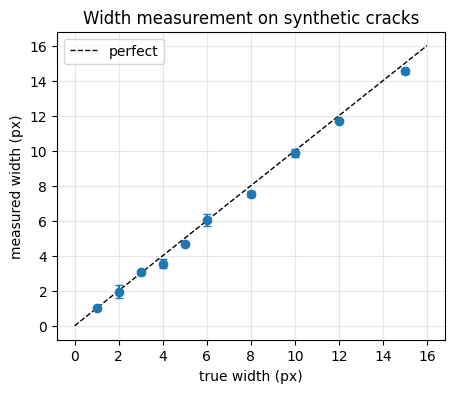

In [3]:
# Cell 3 — Check the method on synthetic cracks of known width
def synthetic_crack(width, size=400):
    x = np.linspace(20, size - 20, 600)
    y = size / 2 + sum(rng.uniform(10, 40) * np.sin(rng.uniform(0.5, 3) * 2 * np.pi * x / size + rng.uniform(0, 6))
                       for _ in range(2))
    canvas = np.full((size, size), 255, np.uint8)
    cv2.polylines(canvas, [np.stack([x, y], 1).round().astype(np.int32)], False, 0, 1)
    dist_to_line = cv2.distanceTransform(canvas, cv2.DIST_L2, cv2.DIST_MASK_PRECISE)
    return dist_to_line <= width / 2

rows = []
for true_w in [1, 2, 3, 4, 5, 6, 8, 10, 12, 15]:
    for _ in range(20):
        m = measure_crack(synthetic_crack(true_w))
        rows.append({"true_width": true_w, "measured": m["median_w"]})
synthetic = pd.DataFrame(rows)
check = synthetic.groupby("true_width")["measured"].agg(["mean", "std"]).round(2)
check["error"] = (check["mean"] - check.index).round(2)
print(check)

plt.figure(figsize=(5, 4))
plt.errorbar(check.index, check["mean"], yerr=check["std"], fmt="o", capsize=3)
plt.plot([0, 16], [0, 16], "k--", lw=1, label="perfect")
plt.xlabel("true width (px)")
plt.ylabel("measured width (px)")
plt.title("Width measurement on synthetic cracks")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

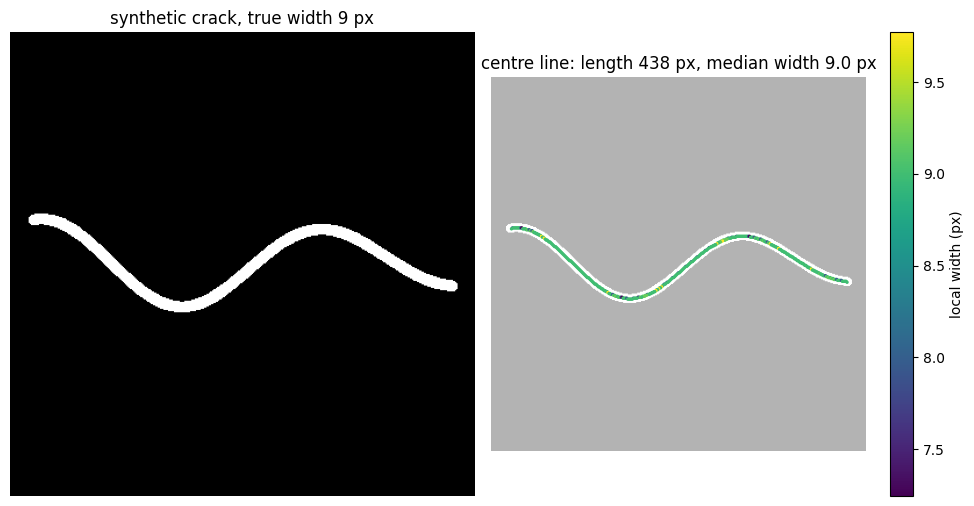

In [4]:
# Cell 4 — What the measurement sees: centre line coloured by width
example = synthetic_crack(9)
m = measure_crack(example)
width_map = np.full(example.shape, np.nan)
width_map[m["skeleton"]] = m["widths"]
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(example, cmap="gray")
axes[0].set_title("synthetic crack, true width 9 px")
axes[1].imshow(example, cmap="gray", alpha=0.3)
ys, xs = np.nonzero(m["skeleton"])
sc = axes[1].scatter(xs, ys, c=m["widths"], s=2, cmap="viridis")
plt.colorbar(sc, ax=axes[1], label="local width (px)")
axes[1].set_title(f"centre line: length {m['length_px']:.0f} px, median width {m['median_w']:.1f} px")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

In [5]:
# Cell 5 — Index, splits and predictions (same as Stage 4)
TRAIN_SOURCES = ["CRACK500", "Rissbilder", "Noncrack", "Volker", "GAPS384", "Misc"]
UNSEEN_SOURCES = ["DeepCrack", "CFD", "Ceramic"]
EXCLUDED_SOURCES = ["CrackTree200"]
SPLIT_FRACTIONS = {"train": 0.8, "val": 0.1, "test_seen": 0.1}
folders = {p.name: p for p in DATA_ROOT.rglob("*") if p.is_dir() and p.name in {"Images", "Images-2", "Masks"}}
SOURCE_RULES = [("CRACK500", "CRACK500"), ("Rissbilder", "Rissbilder"), ("noncrack", "Noncrack"),
                ("DeepCrack", "DeepCrack"), ("Volker", "Volker"), ("GAPS384", "GAPS384"),
                ("cracktree200", "CrackTree200"), ("CFD", "CFD"), ("Ceramic", "Ceramic")]

def source_of(name):
    for prefix, source in SOURCE_RULES:
        if name.startswith(prefix):
            return source
    return "Misc"

def parent_of(name, source):
    stem = name.rsplit(".", 1)[0]
    parts = stem.split("_")
    if source in ("CRACK500", "GAPS384"):
        return "_".join(parts[1:3])
    if source == "Rissbilder":
        return parts[3]
    if source == "Volker":
        return parts[1]
    if source == "Noncrack":
        return "_".join(parts[:5])
    if source == "DeepCrack":
        return stem.split("_", 1)[1].split("-")[0]
    if source == "Misc":
        return "_".join(parts[:2])
    return stem

def assign_splits(frame, fractions, seed=0):
    r = np.random.default_rng(seed)
    split_of_parent = {}
    for source in TRAIN_SOURCES:
        parents = np.array(sorted(frame.loc[frame["source"] == source, "parent"].unique()))
        r.shuffle(parents)
        n_train = int(round(fractions["train"] * len(parents)))
        n_val = int(round(fractions["val"] * len(parents)))
        for k, parent in enumerate(parents):
            split_of_parent[parent] = "train" if k < n_train else "val" if k < n_train + n_val else "test_seen"
    split = frame["parent"].map(split_of_parent)
    split[frame["source"].isin(UNSEEN_SOURCES)] = "test_unseen"
    split[frame["source"].isin(EXCLUDED_SOURCES)] = "excluded"
    return split

rows = []
for folder in ("Images", "Images-2"):
    for p in sorted(folders[folder].glob("*.png")):
        s = source_of(p.name)
        rows.append({"name": p.name, "source": s, "parent": f"{s}/{parent_of(p.name, s)}",
                     "image": str(p), "mask": str(folders["Masks"] / p.name)})
df = pd.DataFrame(rows)
df["split"] = assign_splits(df, SPLIT_FRACTIONS)
eval_df = df[df["split"].isin(["val", "test_seen", "test_unseen"])].reset_index(drop=True)

def load_mask(path):
    arr = np.array(Image.open(path).convert("L"))
    return arr > (127 if arr.max() > 1 else 0)

checkpoint = sorted(Path(r) / f for r, _, fs in os.walk(DATA_ROOT, followlinks=True)
                    for f in fs if f.startswith("best_") and f.endswith(".pth"))[0]
model = smp.Unet(encoder_name="resnet34", encoder_weights=None, in_channels=3, classes=1)
model.load_state_dict(torch.load(checkpoint, map_location=DEVICE))
model = model.to(DEVICE).eval()
print("model:", checkpoint.name)

eval_tf = A.Compose([A.PadIfNeeded(min_height=PAD, min_width=PAD, border_mode=cv2.BORDER_REFLECT_101),
                     A.Normalize(), ToTensorV2()])

class ImageOnly(Dataset):
    def __init__(self, paths):
        self.paths = paths

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        return eval_tf(image=np.array(Image.open(self.paths[i]).convert("RGB")))["image"]

preds = []
with torch.no_grad():
    for images in tqdm(DataLoader(ImageOnly(eval_df["image"].tolist()), batch_size=16, num_workers=2)):
        with torch.autocast(DEVICE.type, enabled=DEVICE.type == "cuda"):
            logits = model(images.to(DEVICE))
        p = torch.sigmoid(logits.float())[:, 0, BORDER:-BORDER, BORDER:-BORDER]
        preds.extend((p >= THRESHOLD).cpu().numpy())
print(len(preds), "predictions")

model: best_resnet34_seed0.pth


  0%|          | 0/153 [00:00<?, ?it/s]

2434 predictions


In [6]:
# Cell 6 — Measure label and prediction in every image
rows = []
for i, row in tqdm(eval_df.iterrows(), total=len(eval_df)):
    label = load_mask(row["mask"])
    if label.sum() < MIN_CRACK_PX or preds[i].sum() < MIN_CRACK_PX:
        continue
    ml, mp = measure_crack(label), measure_crack(preds[i])
    rows.append({"idx": i, "name": row["name"], "source": row["source"], "split": row["split"],
                 "label_w": ml["median_w"], "pred_w": mp["median_w"],
                 "label_len": ml["length_px"], "pred_len": mp["length_px"]})
widths = pd.DataFrame(rows)
widths["ratio"] = widths["pred_w"] / widths["label_w"]

per_source = widths.groupby(["split", "source"]).agg(
    images=("name", "size"),
    label_width_px=("label_w", "median"),
    pred_width_px=("pred_w", "median"),
    width_ratio=("ratio", "median"),
    length_ratio=("pred_len", lambda s: np.median(s / widths.loc[s.index, "label_len"])),
).round(2)
print(per_source.to_string())

  0%|          | 0/2434 [00:00<?, ?it/s]

                        images  label_width_px  pred_width_px  width_ratio  length_ratio
split       source                                                                      
test_seen   CRACK500       342           15.00          17.97         1.27          0.88
            GAPS384         40            3.00           5.00         1.39          0.99
            Misc            31           15.00          16.89         1.12          0.96
            Rissbilder     311            3.47           5.00         1.53          1.14
            Volker          39            9.00           7.00         0.78          0.97
test_unseen CFD            117            3.00           6.21         2.33          0.84
            Ceramic         80            4.66           6.21         1.67          1.08
            DeepCrack      438            5.00           9.00         1.86          0.86
val         CRACK500       283           13.56          17.97         1.24          0.90
            GAPS384  

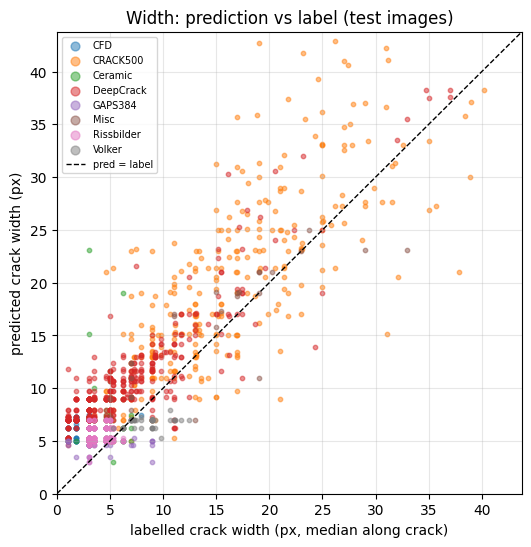

In [7]:
# Cell 7 — Predicted vs labelled width, per image
fig, ax = plt.subplots(figsize=(6, 6))
for source, g in widths[widths["split"] != "val"].groupby("source"):
    ax.scatter(g["label_w"], g["pred_w"], s=10, alpha=0.5, label=source)
lim = widths[["label_w", "pred_w"]].quantile(0.99).max()
ax.plot([0, lim], [0, lim], "k--", lw=1, label="pred = label")
ax.set_xlim(0, lim)
ax.set_ylim(0, lim)
ax.set_xlabel("labelled crack width (px, median along crack)")
ax.set_ylabel("predicted crack width (px)")
ax.set_title("Width: prediction vs label (test images)")
ax.legend(fontsize=7, markerscale=2)
ax.grid(alpha=0.3)
plt.show()

In [8]:
# Cell 8 — Correct the width bias, fitted on validation only
val = widths[widths["split"] == "val"]
slope, intercept = np.polyfit(val["pred_w"], val["label_w"], 1)
print(f"fitted on {len(val)} validation images: label_w = {slope:.2f} x pred_w + {intercept:+.2f} px")
widths["corrected_w"] = slope * widths["pred_w"] + intercept

test = widths[widths["split"] != "val"]
summary = test.groupby("source").apply(lambda g: pd.Series({
    "images": len(g),
    "bias raw (px)": (g["pred_w"] - g["label_w"]).median(),
    "bias corrected (px)": (g["corrected_w"] - g["label_w"]).median(),
    "MAE raw (px)": (g["pred_w"] - g["label_w"]).abs().median(),
    "MAE corrected (px)": (g["corrected_w"] - g["label_w"]).abs().median(),
}), include_groups=False).round(2)
print(summary.to_string())

fitted on 588 validation images: label_w = 0.89 x pred_w + -0.49 px
            images  bias raw (px)  bias corrected (px)  MAE raw (px)  MAE corrected (px)
source                                                                                  
CFD          117.0           4.00                 2.74          4.00                2.74
CRACK500     342.0           3.35                 1.15          4.01                3.10
Ceramic       80.0           2.32                 1.13          2.32                1.34
DeepCrack    438.0           4.25                 2.74          4.25                2.88
GAPS384       40.0           1.54                 0.44          1.96                0.98
Misc          31.0           1.99                -0.61          2.20                2.04
Rissbilder   311.0           1.85                 0.78          1.85                0.96
Volker        39.0          -2.00                -3.26          2.00                3.26


In [9]:
# Cell 9 — From pixels to millimetres and a code check (illustration)
def assess(width_px, mm_per_px, limit_mm=LIMIT_MM):
    width_mm = round(width_px * mm_per_px, 2)
    return width_mm, "exceeds limit" if width_mm > limit_mm else "within limit"

MM_PER_PX = 0.1   # ASSUMED for illustration: a 40 mm field of view across 400 px. CrackSeg9k has no scale.
examples = test[test["source"] == "DeepCrack"].sample(5, random_state=0)
for _, r in examples.iterrows():
    w_mm, verdict_pred = assess(r["corrected_w"], MM_PER_PX)
    l_mm, verdict_label = assess(r["label_w"], MM_PER_PX)
    print(f"{r['name'][:28]:28s} model {w_mm:.2f} mm ({verdict_pred:13s}) | label {l_mm:.2f} mm ({verdict_label})")
print(f"\nAt {MM_PER_PX} mm/px, a 1-pixel width error is {MM_PER_PX:.1f} mm - a third of the {LIMIT_MM} mm limit.")

DeepCrack_11247-7.png        model 0.77 mm (exceeds limit) | label 1.03 mm (exceeds limit)
DeepCrack_IMG25-5.png        model 0.57 mm (exceeds limit) | label 0.30 mm (within limit)
DeepCrack_11289-11.png       model 0.93 mm (exceeds limit) | label 0.50 mm (exceeds limit)
DeepCrack_7Q3A9064-4.png     model 1.15 mm (exceeds limit) | label 0.92 mm (exceeds limit)
DeepCrack_11148.png          model 0.66 mm (exceeds limit) | label 0.35 mm (exceeds limit)

At 0.1 mm/px, a 1-pixel width error is 0.1 mm - a third of the 0.3 mm limit.


In [10]:
# Cell 10 — Save
widths.to_csv(OUT_DIR / "widths_per_image.csv", index=False)
per_source.to_csv(OUT_DIR / "widths_per_source.csv")
summary.to_csv(OUT_DIR / "width_bias_summary.csv")
check.to_csv(OUT_DIR / "synthetic_check.csv")
json.dump({"slope": slope, "intercept": intercept}, open(OUT_DIR / "width_correction.json", "w"))
print("saved")

saved
